## LeNet CNN Implementation

In [17]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras.layers import Dense, Convolution2D, Flatten, AveragePooling2D, Input
from keras import Sequential
from keras.datasets import mnist

### Load MNIST Data

In [18]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

### Preprocess the images

In [19]:
# Normalize pixel values to [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Resize images from 28x28 to 32x32
X_train = tf.image.resize(X_train[..., np.newaxis], (32, 32)).numpy()
X_test = tf.image.resize(X_test[..., np.newaxis], (32, 32)).numpy()

print("Processed training data:", X_train.shape)
print("Processed testing data:", X_test.shape)

Processed training data: (60000, 32, 32, 1)
Processed testing data: (10000, 32, 32, 1)


### LeNet Architecture

In [20]:
model = Sequential([
    Input(shape=(32, 32, 1)),

    # Convolutional layer 1
    Convolution2D(6, kernel_size=(5, 5), padding="valid", activation="tanh"),
    AveragePooling2D(pool_size=(2, 2), strides=2, padding="valid"),

    # Convolutional layer 2
    Convolution2D(16, kernel_size=(5, 5), padding="valid", activation="tanh"),
    AveragePooling2D(pool_size=(2, 2), strides=2, padding="valid"),

    # Fully connected layers
    Flatten(),
    Dense(120, activation="tanh"),
    Dense(84, activation="tanh"),
    Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_4             │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_5             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Training

In [22]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 25s 46ms/step - accuracy: 0.8991 - loss: 0.3555 - val_accuracy: 0.9635 - val_loss: 0.1372
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 15s 36ms/step - accuracy: 0.9641 - loss: 0.1213 - val_accuracy: 0.9752 - val_loss: 0.0899
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 39ms/step - accuracy: 0.9771 - loss: 0.0773 - val_accuracy: 0.9802 - val_loss: 0.0650
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 37ms/step - accuracy: 0.9823 - loss: 0.0579 - val_accuracy: 0.9838 - val_loss: 0.0543
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - accuracy: 0.9860 - loss: 0.0440 - val_accuracy: 0.9843 - val_loss: 0.0547
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 41ms/step - accuracy: 0.9892 - loss: 0.0364 - val_accuracy: 0.9832 - val_loss: 0.0519
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - accuracy: 0.9909 - loss: 0.0290 - val_accuracy: 0.9843 - val_loss: 0.0533
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 43ms/step - accuracy: 0.9929 - loss: 0.0240 - 

### Plots

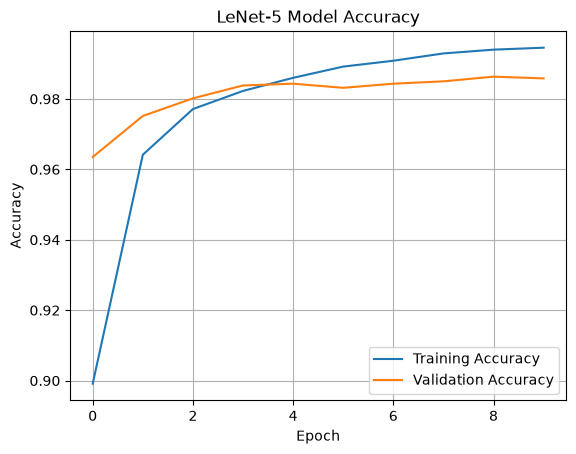

In [23]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("LeNet-5 Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

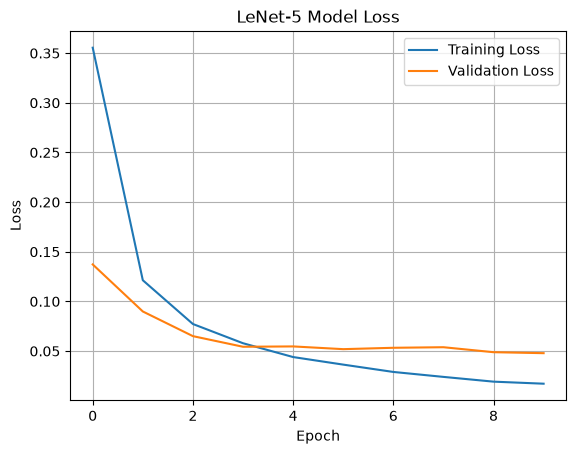

In [24]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LeNet-5 Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [25]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.0464
Test Accuracy: 98.59%


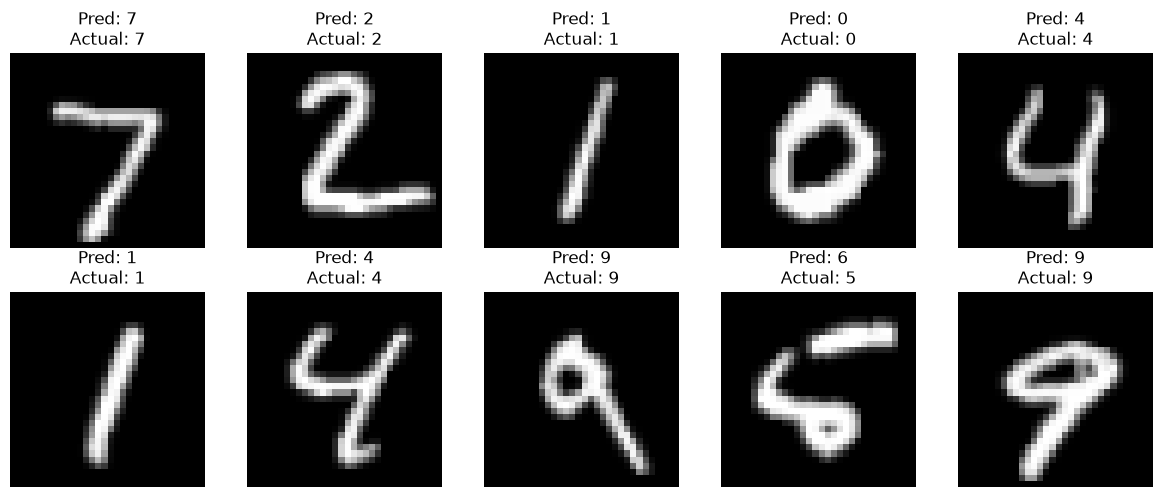

In [26]:
import numpy as np

predictions = model.predict(X_test[:10], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].squeeze(), cmap="gray")
    plt.title(f"Pred: {predicted_labels[i]}\nActual: {y_test[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()